Da li je bottleneck od 16 neurona predimenzionisan i da li bi manji broj neurona zadrzao slicne performanse?<br>
Da li razlicita obucavanja istog modela formiraju stabilnu reprezentacionu strukturu?

In [1]:
from pathlib import Path
import copy
import random
import joblib
import time
from matplotlib import pyplot as plt

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import (
    DataLoader,
    TensorDataset
)

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    precision_recall_curve
)

In [2]:
PROJECT_ROOT = Path.cwd().parent

MODELING_DATA_DIR = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "modeling"
)

MODEL_DIR = (
    PROJECT_ROOT
    / "models"
)

REPRESENTATIONS_DIR = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "representations"
)

TABLES_DIR = (
    PROJECT_ROOT
    / "reports"
    / "tables"
)

FIGURES_DIR = (
    PROJECT_ROOT
    / "reports"
    / "figures"
)

STABILITY_MODEL_DIR = (
    MODEL_DIR
    / "bottleneck_stability"
)

STABILITY_REPRESENTATIONS_DIR = (
    REPRESENTATIONS_DIR
    / "bottleneck_stability"
)

STABILITY_MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

STABILITY_REPRESENTATIONS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

TABLES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

In [3]:
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print(
    "Uređaj:",
    device
)

Uređaj: cuda


In [4]:
def set_random_seed(seed):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

In [5]:
X_train = joblib.load(
    MODELING_DATA_DIR
    / "X_train_target_diag.joblib"
)

X_val = joblib.load(
    MODELING_DATA_DIR
    / "X_val_target_diag.joblib"
)

X_test = joblib.load(
    MODELING_DATA_DIR
    / "X_test_target_diag.joblib"
)

y_train = joblib.load(
    MODELING_DATA_DIR
    / "y_train.joblib"
)

y_val = joblib.load(
    MODELING_DATA_DIR
    / "y_val.joblib"
)

y_test = joblib.load(
    MODELING_DATA_DIR
    / "y_test.joblib"
)

In [6]:
def convert_features_to_numpy(features):

    if hasattr(features, "toarray"):
        features = features.toarray()

    if hasattr(features, "to_numpy"):
        features = features.to_numpy()

    return np.asarray(
        features,
        dtype=np.float32
    )

In [7]:
def convert_labels_to_numpy(labels):

    if hasattr(labels, "to_numpy"):
        labels = labels.to_numpy()

    return (
        np.asarray(
            labels,
            dtype=np.float32
        )
        .reshape(-1)
    )

In [8]:
X_train = convert_features_to_numpy(
    X_train
)

X_val = convert_features_to_numpy(
    X_val
)

X_test = convert_features_to_numpy(
    X_test
)

y_train = convert_labels_to_numpy(
    y_train
)

y_val = convert_labels_to_numpy(
    y_val
)

y_test = convert_labels_to_numpy(
    y_test
)

In [9]:
print(
    "X_train:",
    X_train.shape,
    X_train.dtype
)

print(
    "X_val:",
    X_val.shape,
    X_val.dtype
)

print(
    "X_test:",
    X_test.shape,
    X_test.dtype
)

print(
    "y_train:",
    y_train.shape,
    y_train.dtype
)

print(
    "y_val:",
    y_val.shape,
    y_val.dtype
)

print(
    "y_test:",
    y_test.shape,
    y_test.dtype
)

X_train: (59604, 168) float32
X_val: (19868, 168) float32
X_test: (19868, 168) float32
y_train: (59604,) float32
y_val: (19868,) float32
y_test: (19868,) float32


In [10]:
for split_name, labels in {
    "train": y_train,
    "validation": y_val,
    "test": y_test
}.items():

    class_values, class_counts = np.unique(
        labels,
        return_counts=True
    )

    print(
        split_name,
        dict(
            zip(
                class_values.astype(int),
                class_counts
            )
        )
    )

train {np.int64(0): np.int64(52816), np.int64(1): np.int64(6788)}
validation {np.int64(0): np.int64(17605), np.int64(1): np.int64(2263)}
test {np.int64(0): np.int64(17605), np.int64(1): np.int64(2263)}


In [11]:
original_model_state_dict = torch.load(
    MODEL_DIR / "optimized_mlp_model.pt",
    map_location="cpu",
    weights_only=True
)

for parameter_name, parameter_values in (
    original_model_state_dict.items()
):
    print(
        parameter_name,
        tuple(parameter_values.shape)
    )

fc1.weight (256, 168)
fc1.bias (256,)
fc2.weight (128, 256)
fc2.bias (128,)
bottleneck.weight (16, 128)
bottleneck.bias (16,)
output.weight (1, 16)
output.bias (1,)


Parametri i klasa dosledni optimizovanom MLP-u.

In [12]:
INPUT_DIM = X_train.shape[1]

HIDDEN_DIMS = [
    256,
    128
]

BOTTLENECK_DIMENSIONS = [
    2,
    4,
    16
]

RANDOM_SEEDS = [
    42,
    123,
    2026
]

DROPOUT_RATE = 0.0
LEARNING_RATE = 0.003
WEIGHT_DECAY = 0.0
BATCH_SIZE = 128
MAX_EPOCHS = 50
PATIENCE = 5

print(
    "Ulazna dimenzija:",
    INPUT_DIM
)

print(
    "Skriveni slojevi:",
    HIDDEN_DIMS
)

print(
    "Bottleneck veličine:",
    BOTTLENECK_DIMENSIONS
)

print(
    "Seed vrednosti:",
    RANDOM_SEEDS
)

print(
    "Ukupan broj modela:",
    len(BOTTLENECK_DIMENSIONS)
    * len(RANDOM_SEEDS)
)

Ulazna dimenzija: 168
Skriveni slojevi: [256, 128]
Bottleneck veličine: [2, 4, 16]
Seed vrednosti: [42, 123, 2026]
Ukupan broj modela: 9


In [13]:
class BottleneckMLP(nn.Module):

    def __init__(
        self,
        input_dim,
        hidden_dims,
        bottleneck_dim,
        dropout=0.0
    ):
        super().__init__()

        self.fc1 = nn.Linear(
            input_dim,
            hidden_dims[0]
        )

        self.fc2 = nn.Linear(
            hidden_dims[0],
            hidden_dims[1]
        )

        self.bottleneck = nn.Linear(
            hidden_dims[1],
            bottleneck_dim
        )

        self.output = nn.Linear(
            bottleneck_dim,
            1
        )

        self.relu = nn.ReLU()

        self.dropout = nn.Dropout(
            dropout
        )

    def forward(
        self,
        x,
        return_bottleneck=False
    ):

        hidden_1 = self.relu(
            self.fc1(x)
        )

        hidden_1 = self.dropout(
            hidden_1
        )

        hidden_2 = self.relu(
            self.fc2(hidden_1)
        )

        hidden_2 = self.dropout(
            hidden_2
        )

        bottleneck_values = self.relu(
            self.bottleneck(hidden_2)
        )

        logits = self.output(
            bottleneck_values
        )

        if return_bottleneck:
            return (
                logits,
                bottleneck_values
            )

        return logits

Loss funkcija.

In [14]:
num_positive = float(
    y_train.sum()
)

num_negative = float(
    len(y_train) - num_positive
)

pos_weight_value = (
    num_negative
    / num_positive
)

pos_weight = torch.tensor(
    [pos_weight_value],
    dtype=torch.float32,
    device=device
)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

print(
    "Broj pozitivnih primera:",
    int(num_positive)
)

print(
    "Broj negativnih primera:",
    int(num_negative)
)

print(
    "Težina pozitivne klase:",
    float(pos_weight.item())
)

Broj pozitivnih primera: 6788
Broj negativnih primera: 52816
Težina pozitivne klase: 7.780789852142334


In [15]:
X_train_tensor = torch.as_tensor(
    X_train,
    dtype=torch.float32
)

X_val_tensor = torch.as_tensor(
    X_val,
    dtype=torch.float32
)

X_test_tensor = torch.as_tensor(
    X_test,
    dtype=torch.float32
)

y_train_tensor = torch.as_tensor(
    y_train,
    dtype=torch.float32
).view(-1, 1)

y_val_tensor = torch.as_tensor(
    y_val,
    dtype=torch.float32
).view(-1, 1)

y_test_tensor = torch.as_tensor(
    y_test,
    dtype=torch.float32
).view(-1, 1)

In [16]:
train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

val_dataset = TensorDataset(
    X_val_tensor,
    y_val_tensor
)

test_dataset = TensorDataset(
    X_test_tensor,
    y_test_tensor
)

print(
    "Broj trening primera:",
    len(train_dataset)
)

print(
    "Broj validacionih primera:",
    len(val_dataset)
)

print(
    "Broj test primera:",
    len(test_dataset)
)

Broj trening primera: 59604
Broj validacionih primera: 19868
Broj test primera: 19868


In [17]:
def create_data_loaders(seed):

    generator = torch.Generator()

    generator.manual_seed(
        seed
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=0,
        pin_memory=(
            device.type == "cuda"
        )
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=(
            device.type == "cuda"
        )
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=(
            device.type == "cuda"
        )
    )

    return (
        train_loader,
        val_loader,
        test_loader
    )

In [18]:
def calculate_average_loss(
    model,
    data_loader,
    criterion
):

    model.eval()

    total_loss = 0.0
    total_examples = 0

    with torch.no_grad():

        for batch_features, batch_labels in data_loader:

            batch_features = batch_features.to(
                device
            )

            batch_labels = batch_labels.to(
                device
            )

            logits = model(
                batch_features
            )

            loss = criterion(
                logits,
                batch_labels
            )

            batch_size = batch_features.shape[0]

            total_loss += (
                loss.item()
                * batch_size
            )

            total_examples += batch_size

    average_loss = (
        total_loss
        / total_examples
    )

    return average_loss

Definisemo funkciju koja obucava jedan model za zadatu velicinu bottleneck-a i jednu seed vrednost. Kasnije cemo je pozvati 9 puta.

In [19]:
def collect_outputs(
    model,
    data_loader
):

    model.eval()

    probabilities = []
    labels = []
    bottleneck_values = []

    with torch.no_grad():

        for batch_features, batch_labels in data_loader:

            batch_features = batch_features.to(
                device
            )

            logits, batch_bottleneck = model(
                batch_features,
                return_bottleneck=True
            )

            probabilities.append(
                torch.sigmoid(logits)
                .cpu()
                .numpy()
                .reshape(-1)
            )

            labels.append(
                batch_labels
                .cpu()
                .numpy()
                .reshape(-1)
            )

            bottleneck_values.append(
                batch_bottleneck
                .cpu()
                .numpy()
            )

    return {
        "probabilities": np.concatenate(
            probabilities
        ),
        "labels": np.concatenate(
            labels
        ).astype(int),
        "bottleneck": np.concatenate(
            bottleneck_values,
            axis=0
        )
    }


def train_and_evaluate_model(
    bottleneck_dim,
    seed
):

    set_random_seed(seed)

    train_loader, val_loader, test_loader = (
        create_data_loaders(seed)
    )

    model = BottleneckMLP(
        input_dim=INPUT_DIM,
        hidden_dims=HIDDEN_DIMS,
        bottleneck_dim=bottleneck_dim,
        dropout=DROPOUT_RATE
    ).to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    best_validation_loss = float("inf")
    best_model_state = None
    best_epoch = 0
    epochs_without_improvement = 0

    start_time = time.time()

    for epoch in range(
        1,
        MAX_EPOCHS + 1
    ):

        model.train()

        for batch_features, batch_labels in train_loader:

            batch_features = batch_features.to(
                device
            )

            batch_labels = batch_labels.to(
                device
            )

            optimizer.zero_grad()

            logits = model(
                batch_features
            )

            loss = criterion(
                logits,
                batch_labels
            )

            loss.backward()
            optimizer.step()

        validation_loss = calculate_average_loss(
            model,
            val_loader,
            criterion
        )

        if validation_loss < best_validation_loss:

            best_validation_loss = (
                validation_loss
            )

            best_model_state = copy.deepcopy(
                model.state_dict()
            )

            best_epoch = epoch
            epochs_without_improvement = 0

        else:

            epochs_without_improvement += 1

        if (
            epochs_without_improvement
            >= PATIENCE
        ):
            break

    model.load_state_dict(
        best_model_state
    )

    validation_outputs = collect_outputs(
        model,
        val_loader
    )

    test_outputs = collect_outputs(
        model,
        test_loader
    )

    precision_values, recall_values, thresholds = (
        precision_recall_curve(
            validation_outputs["labels"],
            validation_outputs[
                "probabilities"
            ]
        )
    )

    validation_f1_values = (
        2
        * precision_values[:-1]
        * recall_values[:-1]
        / (
            precision_values[:-1]
            + recall_values[:-1]
            + 1e-12
        )
    )

    best_threshold_index = np.argmax(
        validation_f1_values
    )

    optimal_threshold = float(
        thresholds[
            best_threshold_index
        ]
    )

    test_probabilities = test_outputs[
        "probabilities"
    ]

    test_labels = test_outputs[
        "labels"
    ]

    test_predictions = (
        test_probabilities
        >= optimal_threshold
    ).astype(int)

    test_bottleneck = test_outputs[
        "bottleneck"
    ]

    active_dimensions = int(
        np.any(
            test_bottleneck > 0,
            axis=0
        ).sum()
    )

    model_path = (
        STABILITY_MODEL_DIR
        / (
            f"bottleneck_dim_"
            f"{bottleneck_dim}_"
            f"seed_{seed}.pt"
        )
    )

    torch.save(
        best_model_state,
        model_path
    )

    representation_path = (
        STABILITY_REPRESENTATIONS_DIR
        / (
            f"bottleneck_dim_"
            f"{bottleneck_dim}_"
            f"seed_{seed}.npz"
        )
    )

    np.savez_compressed(
        representation_path,
        bottleneck=test_bottleneck,
        probabilities=test_probabilities,
        labels=test_labels
    )

    return {
        "bottleneck_dim": bottleneck_dim,
        "seed": seed,
        "best_epoch": best_epoch,
        "best_validation_loss":
            best_validation_loss,
        "optimal_threshold":
            optimal_threshold,
        "test_accuracy":
            accuracy_score(
                test_labels,
                test_predictions
            ),
        "test_precision":
            precision_score(
                test_labels,
                test_predictions,
                zero_division=0
            ),
        "test_recall":
            recall_score(
                test_labels,
                test_predictions,
                zero_division=0
            ),
        "test_f1":
            f1_score(
                test_labels,
                test_predictions,
                zero_division=0
            ),
        "test_roc_auc":
            roc_auc_score(
                test_labels,
                test_probabilities
            ),
        "active_dimensions":
            active_dimensions,
        "inactive_dimensions":
            bottleneck_dim
            - active_dimensions,
        "training_time_seconds":
            time.time() - start_time
    }

In [20]:
experiment_results = []

for bottleneck_dim in BOTTLENECK_DIMENSIONS:

    for seed in RANDOM_SEEDS:

        print(
            f"Obučavanje: bottleneck "
            f"{bottleneck_dim}, seed {seed}"
        )

        result = train_and_evaluate_model(
            bottleneck_dim=bottleneck_dim,
            seed=seed
        )

        experiment_results.append(
            result
        )

        print(
            f"ROC-AUC: "
            f"{result['test_roc_auc']:.4f} | "
            f"F1: "
            f"{result['test_f1']:.4f} | "
            f"aktivne dimenzije: "
            f"{result['active_dimensions']}/"
            f"{bottleneck_dim}"
        )

Obučavanje: bottleneck 2, seed 42
ROC-AUC: 0.5000 | F1: 0.2045 | aktivne dimenzije: 0/2
Obučavanje: bottleneck 2, seed 123
ROC-AUC: 0.6760 | F1: 0.2811 | aktivne dimenzije: 1/2
Obučavanje: bottleneck 2, seed 2026
ROC-AUC: 0.6741 | F1: 0.2854 | aktivne dimenzije: 1/2
Obučavanje: bottleneck 4, seed 42
ROC-AUC: 0.6756 | F1: 0.2814 | aktivne dimenzije: 2/4
Obučavanje: bottleneck 4, seed 123
ROC-AUC: 0.6755 | F1: 0.2893 | aktivne dimenzije: 3/4
Obučavanje: bottleneck 4, seed 2026
ROC-AUC: 0.6774 | F1: 0.2816 | aktivne dimenzije: 2/4
Obučavanje: bottleneck 16, seed 42
ROC-AUC: 0.6775 | F1: 0.2855 | aktivne dimenzije: 11/16
Obučavanje: bottleneck 16, seed 123
ROC-AUC: 0.6756 | F1: 0.2886 | aktivne dimenzije: 12/16
Obučavanje: bottleneck 16, seed 2026
ROC-AUC: 0.6780 | F1: 0.2836 | aktivne dimenzije: 11/16


In [21]:
experiment_results_df = pd.DataFrame(
    experiment_results
)

experiment_results_df = (
    experiment_results_df
    .sort_values(
        by=[
            "bottleneck_dim",
            "seed"
        ]
    )
    .reset_index(drop=True)
)

results_path = (
    TABLES_DIR
    / "bottleneck_stability_results.csv"
)

experiment_results_df.to_csv(
    results_path,
    index=False
)

experiment_results_df.round(6)

,bottleneck_dim,seed,best_epoch,best_validation_loss,optimal_threshold,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc,active_dimensions,inactive_dimensions,training_time_seconds
0,2,42,1,1.228499,0.501090,0.113902,0.113902,1.000000,0.204510,0.500000,0,2,8.327979
1,2,123,5,1.149601,0.541759,0.675810,0.188023,0.556341,0.281058,0.675990,1,1,13.667625
2,2,2026,3,1.147327,0.570664,0.738373,0.207144,0.458683,0.285400,0.674107,1,1,8.612922
3,4,42,6,1.152954,0.545796,0.686883,0.190491,0.538224,0.281391,0.675617,2,2,11.697204
4,4,123,3,1.149753,0.596581,0.748993,0.213504,0.448520,0.289297,0.675476,3,1,8.769012
5,4,2026,3,1.141467,0.550404,0.695692,0.192589,0.523641,0.281606,0.677426,2,2,8.881540
6,16,42,3,1.146985,0.618008,0.760620,0.216253,0.419797,0.285457,0.677518,11,5,9.149456
7,16,123,2,1.143844,0.561576,0.741142,0.210028,0.460893,0.288560,0.675632,12,4,128.147063
8,16,2026,3,1.143093,0.550926,0.709080,0.197071,0.505524,0.283589,0.678008,11,5,14.158831


In [22]:
bottleneck_summary_df = (
    experiment_results_df
    .groupby(
        "bottleneck_dim"
    )
    .agg(
        roc_auc_mean=(
            "test_roc_auc",
            "mean"
        ),
        roc_auc_std=(
            "test_roc_auc",
            "std"
        ),
        f1_mean=(
            "test_f1",
            "mean"
        ),
        f1_std=(
            "test_f1",
            "std"
        ),
        active_dimensions_mean=(
            "active_dimensions",
            "mean"
        )
    )
    .reset_index()
)

summary_path = (
    TABLES_DIR
    / "bottleneck_stability_summary.csv"
)

bottleneck_summary_df.to_csv(
    summary_path,
    index=False
)

bottleneck_summary_df.round(6)

,bottleneck_dim,roc_auc_mean,roc_auc_std,f1_mean,f1_std,active_dimensions_mean
0,2,0.616699,0.101069,0.256989,0.045501,0.666667
1,4,0.676173,0.001087,0.284098,0.004504,2.333333
2,16,0.677053,0.001255,0.285869,0.002511,11.333333


Bottleneck od 4 neurona prakticno postize iste rezultate kao bottleneck sa 16, dok bottleneck od 2 neurona nije dovoljno pouzdan. Model sa 4 neurona prosecno koristi samo 2.33 aktivne dimenzije a ipak radi mnogo stabilnije od modela koji unapred ima samo 2 neurona, sto znaci da dodatni neuroni daju mrezi prostor da tokom obucavanja pronadje stabilniju reprezentaciju, cak i kada ne ostanu svi aktivni.<br>
U prethodnom notebook-u smo primetili dve dominantne grupe : dimenzije 2, 4, 5 pozitivno povezane sa logit-om i 7, 10, 15 i 16 negativno povezane sa logit-om, sto je otvorilo hipotezu da mozda postoje samo dva osnovna latentna obrasca i da bi zato dva neurona bila dovoljna.<br>
<br>
Model sa 16 neurona je obucen sa 3 seed vrednosti, standardne devijacije su veoma male, sto ukazuje da model kroz razlicite inicijalizacije ostvaruje slicne rezultate.<br>
Da bismo jos proverili da li model organizuje test primere na isti nacin potrebno je izracunati CKA izmedju ove 3 16-dimenzionalne bottleneck reprezentacije.

In [23]:
def linear_cka(
    first_representation,
    second_representation
):

    first_representation = np.asarray(
        first_representation,
        dtype=np.float64
    )

    second_representation = np.asarray(
        second_representation,
        dtype=np.float64
    )

    if (
        first_representation.shape[0]
        != second_representation.shape[0]
    ):
        raise ValueError(
            "Reprezentacije moraju imati "
            "isti broj test primera."
        )

    first_centered = (
        first_representation
        - first_representation.mean(
            axis=0,
            keepdims=True
        )
    )

    second_centered = (
        second_representation
        - second_representation.mean(
            axis=0,
            keepdims=True
        )
    )

    cross_covariance = (
        first_centered.T
        @ second_centered
    )

    first_covariance = (
        first_centered.T
        @ first_centered
    )

    second_covariance = (
        second_centered.T
        @ second_centered
    )

    numerator = (
        np.linalg.norm(
            cross_covariance,
            ord="fro"
        ) ** 2
    )

    denominator = (
        np.linalg.norm(
            first_covariance,
            ord="fro"
        )
        * np.linalg.norm(
            second_covariance,
            ord="fro"
        )
    )

    if denominator == 0:
        return np.nan

    return numerator / denominator

In [24]:
CKA_BOTTLENECK_DIM = 16

bottleneck_representations = {}

reference_labels = None

for seed in RANDOM_SEEDS:

    representation_path = (
        STABILITY_REPRESENTATIONS_DIR
        / (
            f"bottleneck_dim_"
            f"{CKA_BOTTLENECK_DIM}_"
            f"seed_{seed}.npz"
        )
    )

    with np.load(
        representation_path
    ) as saved_data:

        representation = saved_data[
            "bottleneck"
        ]

        labels = saved_data[
            "labels"
        ]

    if reference_labels is None:

        reference_labels = labels

    else:

        assert np.array_equal(
            reference_labels,
            labels
        ), (
            "Redosled test primera nije isti "
            "za sve seed vrednosti."
        )

    bottleneck_representations[
        seed
    ] = representation

    active_dimensions = np.sum(
        np.std(
            representation,
            axis=0
        ) > 0
    )

    print(
        f"Seed {seed} | "
        f"oblik: {representation.shape} | "
        f"aktivne dimenzije: "
        f"{active_dimensions}/"
        f"{CKA_BOTTLENECK_DIM}"
    )

Seed 42 | oblik: (19868, 16) | aktivne dimenzije: 11/16
Seed 123 | oblik: (19868, 16) | aktivne dimenzije: 12/16
Seed 2026 | oblik: (19868, 16) | aktivne dimenzije: 11/16


In [25]:
seed_labels = [
    f"seed_{seed}"
    for seed in RANDOM_SEEDS
]

number_of_seeds = len(
    RANDOM_SEEDS
)

cka_matrix = np.zeros(
    (
        number_of_seeds,
        number_of_seeds
    )
)

for first_index, first_seed in enumerate(
    RANDOM_SEEDS
):

    for second_index, second_seed in enumerate(
        RANDOM_SEEDS
    ):

        cka_matrix[
            first_index,
            second_index
        ] = linear_cka(
            bottleneck_representations[
                first_seed
            ],
            bottleneck_representations[
                second_seed
            ]
        )

cka_df = pd.DataFrame(
    cka_matrix,
    index=seed_labels,
    columns=seed_labels
)

cka_df.round(6)

,seed_42,seed_123,seed_2026
seed_42,1.000000,0.81513,0.951503
seed_123,0.815130,1.00000,0.775270
seed_2026,0.951503,0.77527,1.000000


In [26]:
cka_table_path = (
    TABLES_DIR
    / "bottleneck_16_seed_cka_matrix.csv"
)

cka_df.to_csv(
    cka_table_path
)

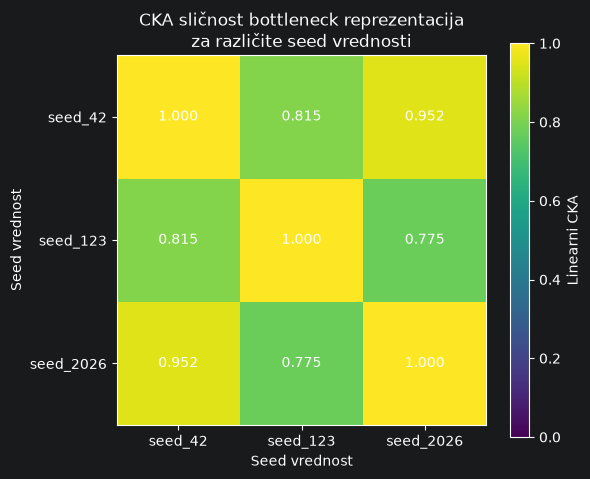

In [27]:
cka_figure_path = (
    FIGURES_DIR
    / "bottleneck_16_seed_cka_heatmap.png"
)

plt.figure(
    figsize=(6, 5)
)

image = plt.imshow(
    cka_matrix,
    vmin=0,
    vmax=1
)

plt.colorbar(
    image,
    label="Linearni CKA"
)

plt.xticks(
    ticks=np.arange(
        number_of_seeds
    ),
    labels=seed_labels
)

plt.yticks(
    ticks=np.arange(
        number_of_seeds
    ),
    labels=seed_labels
)

for row_index in range(
    number_of_seeds
):

    for column_index in range(
        number_of_seeds
    ):

        plt.text(
            column_index,
            row_index,
            f"{cka_matrix[row_index, column_index]:.3f}",
            ha="center",
            va="center"
        )

plt.title(
    "CKA sličnost bottleneck reprezentacija\n"
    "za različite seed vrednosti"
)

plt.xlabel(
    "Seed vrednost"
)

plt.ylabel(
    "Seed vrednost"
)

plt.tight_layout()

plt.savefig(
    cka_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Reprezentacije modela sa 16 neurona su prilicno stabilne za razlicite inicijalizacije.<br>
Prosecna CKA slicnost izmedju seed-ova je 0.847. <br>
Modeli nisu naucili gotovo identicne bottleneck aktivacije, ali u velikoj meri organizuju test primere na slican nacin.